## Importamos todos los paquetes aquí por comodidad

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from scipy import stats

In [2]:
import os
os.getcwd()

'/home/202512789@alu.comillas.edu/Probabilidad y Estadística/TRABAJO 1'

## Cargamos los datos con los que se trabaja

In [3]:
nom_fi_datos_temp = 'G01A_2m_temperature.csv'
nom_fi_datos_irrad = 'G01A_surface_solar_radiation_downwards.csv'
nom_fi_datos_precip = 'G01A_total_precipitation.csv'

In [4]:
ruta_csv = os.path.join(f'{nom_fi_datos_temp}')
df_orig_temp = pd.read_csv(ruta_csv)

# parseamos la fecha (cadena) para que sea un datetime con formato yyyy/mm/dd 
df_orig_temp['FECHA'] = pd.to_datetime(df_orig_temp['FECHA'], format='%Y-%m-%d')

s = df_orig_temp.loc[:,'FECHA']
df_orig_temp['FECHA'] =  s.dt.date

print('Tamaño de df_orig_temp con los datos cargados:', df_orig_temp.shape)
print('Dataframe con todos los datos leidos (filas: días, columnas: variables):')
print(df_orig_temp)

Tamaño de df_orig_temp con los datos cargados: (4383, 15)
Dataframe con todos los datos leidos (filas: días, columnas: variables):
           FECHA  TEMP_CELDA01  TEMP_CELDA02  TEMP_CELDA03  TEMP_CELDA04  \
0     2014-01-01     10.507935     10.184529      9.885254     10.478923   
1     2014-01-02     12.103457     11.748009     11.428368     12.045392   
2     2014-01-03     13.271104     12.917161     12.594407     13.272590   
3     2014-01-04      9.909261      9.564168      9.260661     10.009114   
4     2014-01-05      8.723439      8.405385      8.029063      8.819285   
...          ...           ...           ...           ...           ...   
4378  2025-12-27      6.387714      6.120380      5.803303      6.213235   
4379  2025-12-28      8.558502      8.185231      7.769379      8.415436   
4380  2025-12-29      6.722017      6.538057      6.310599      6.873669   
4381  2025-12-30      7.366825      7.156376      6.944665      7.394962   
4382  2025-12-31      7.053768   

In [5]:
ruta_csv = os.path.join( f'{nom_fi_datos_irrad}')
df_orig_irrad = pd.read_csv(ruta_csv)

# parseamos la fecha (cadena) para que sea un datetime con formato yyyy/mm/dd 
df_orig_irrad['FECHA'] = pd.to_datetime(df_orig_irrad['FECHA'], format='%Y-%m-%d')

s = df_orig_irrad.loc[:,'FECHA']
df_orig_irrad['FECHA'] =  s.dt.date

print('Tamaño de df_orig_irrad con los datos cargados:', df_orig_irrad.shape)
print('Dataframe con todos los datos leidos (filas: días, columnas: variables):')
print(df_orig_irrad)

Tamaño de df_orig_irrad con los datos cargados: (4383, 15)
Dataframe con todos los datos leidos (filas: días, columnas: variables):
           FECHA  IRRAD_CELDA01  IRRAD_CELDA02  IRRAD_CELDA03  IRRAD_CELDA04  \
0     2014-01-01      216153.55     221514.200     226185.420     216941.500   
1     2014-01-02       46182.44      43555.484      41082.902      54423.234   
2     2014-01-03      151202.60     156498.840     161921.550     169761.100   
3     2014-01-04      131521.06     130642.310     130140.600     150176.730   
4     2014-01-05      291939.72     296379.380     301071.620     301388.280   
...          ...            ...            ...            ...            ...   
4378  2025-12-27      219719.12     229198.750     238696.170     198351.880   
4379  2025-12-28      302196.90     300463.500     298154.500     302508.840   
4380  2025-12-29      349713.75     348253.780     345809.720     351148.750   
4381  2025-12-30      314719.75     315519.470     316274.620     31

In [6]:
ruta_csv = os.path.join(f'{nom_fi_datos_precip}')
df_orig_precip = pd.read_csv(ruta_csv)

# parseamos la fecha (cadena) para que sea un datetime con formato yyyy/mm/dd 
df_orig_precip['FECHA'] = pd.to_datetime(df_orig_precip['FECHA'], format='%Y-%m-%d')

s = df_orig_precip.loc[:,'FECHA']
df_orig_precip['FECHA'] =  s.dt.date

print('Tamaño de df_orig_precip con los datos cargados:', df_orig_precip.shape)
print('Dataframe con todos los datos leidos (filas: días, columnas: variables):')
print(df_orig_precip)

Tamaño de df_orig_precip con los datos cargados: (4383, 15)
Dataframe con todos los datos leidos (filas: días, columnas: variables):
           FECHA  PRECIP_CELDA01  PRECIP_CELDA02  PRECIP_CELDA03  \
0     2014-01-01    1.726640e-05    2.184587e-05    2.634153e-05   
1     2014-01-02    1.975207e-04    1.818365e-04    1.648032e-04   
2     2014-01-03    1.714909e-04    2.023070e-04    2.303989e-04   
3     2014-01-04    3.041076e-04    3.009254e-04    2.952680e-04   
4     2014-01-05    4.802520e-07    3.720634e-07    2.610808e-07   
...          ...             ...             ...             ...   
4378  2025-12-27    2.070589e-04    2.158616e-04    2.297312e-04   
4379  2025-12-28    3.717894e-05    5.393328e-05    7.344698e-05   
4380  2025-12-29    1.091532e-05    1.293256e-05    1.453979e-05   
4381  2025-12-30    2.449622e-05    2.759179e-05    3.011753e-05   
4382  2025-12-31    8.997887e-08    6.990027e-08    5.610418e-08   

      PRECIP_CELDA04  PRECIP_CELDA05  PRECIP_CELDA

### 1. Visión general de las series

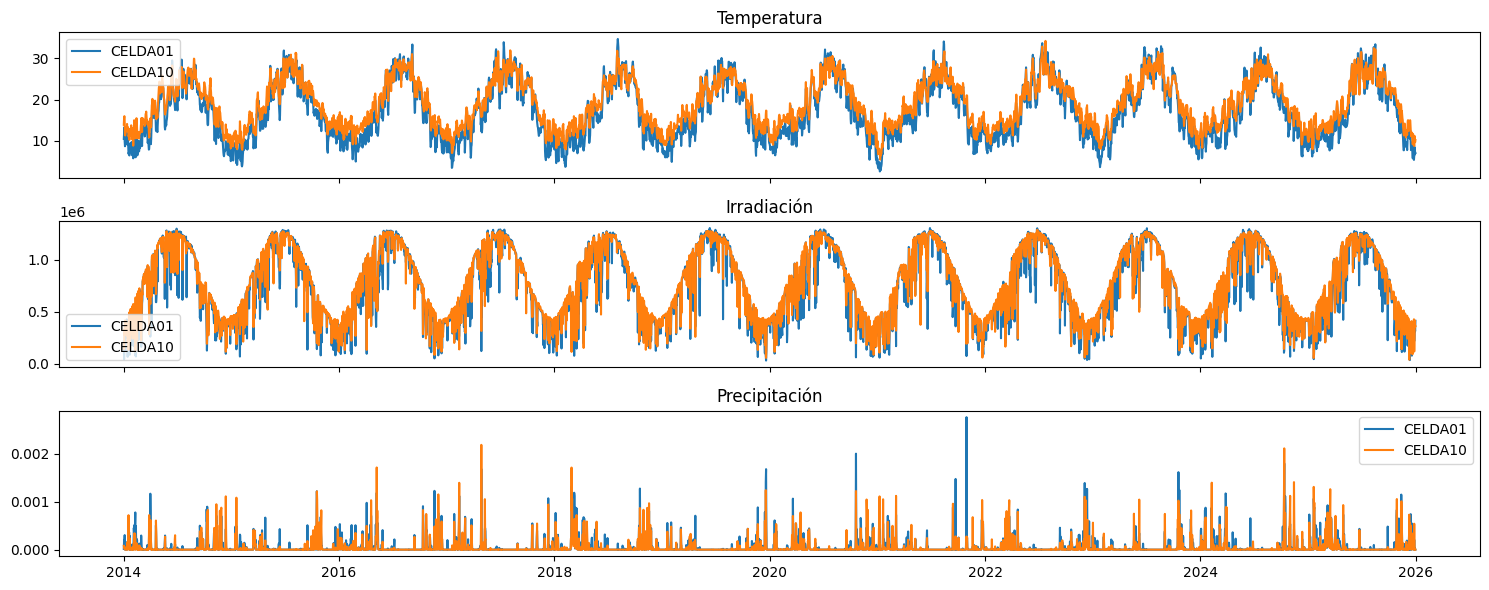

In [7]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(15, 6),
    sharex=True
)

# Temperatura
axes[0].plot(df_orig_temp.FECHA, df_orig_temp.TEMP_CELDA01, label='CELDA01')
axes[0].plot(df_orig_temp.FECHA, df_orig_temp.TEMP_CELDA10, label='CELDA10')
axes[0].set_title('Temperatura')
axes[0].legend()

# Irradiación
axes[1].plot(df_orig_irrad.FECHA, df_orig_irrad.IRRAD_CELDA01, label='CELDA01')
axes[1].plot(df_orig_irrad.FECHA, df_orig_irrad.IRRAD_CELDA10, label='CELDA10')
axes[1].set_title('Irradiación')
axes[1].legend()

# Precipitación
axes[2].plot(df_orig_precip.FECHA, df_orig_precip.PRECIP_CELDA01, label='CELDA01')
axes[2].plot(df_orig_precip.FECHA, df_orig_precip.PRECIP_CELDA10, label='CELDA10')
axes[2].set_title('Precipitación')
axes[2].legend()

plt.tight_layout()
plt.show()


# 1. Estudiar la distribución de la temperatura, la irradiación y la precipitación en las celdas 01 y 10.


### 1.1. ¿Cómo es la distribución de la temperatura en la celda 01? ¿Y cómo es la distribución de la irradiación y la de la precipitación en la celda 01? ¿Cómo se distribuye cada una de estas tres variables en la celda 10?


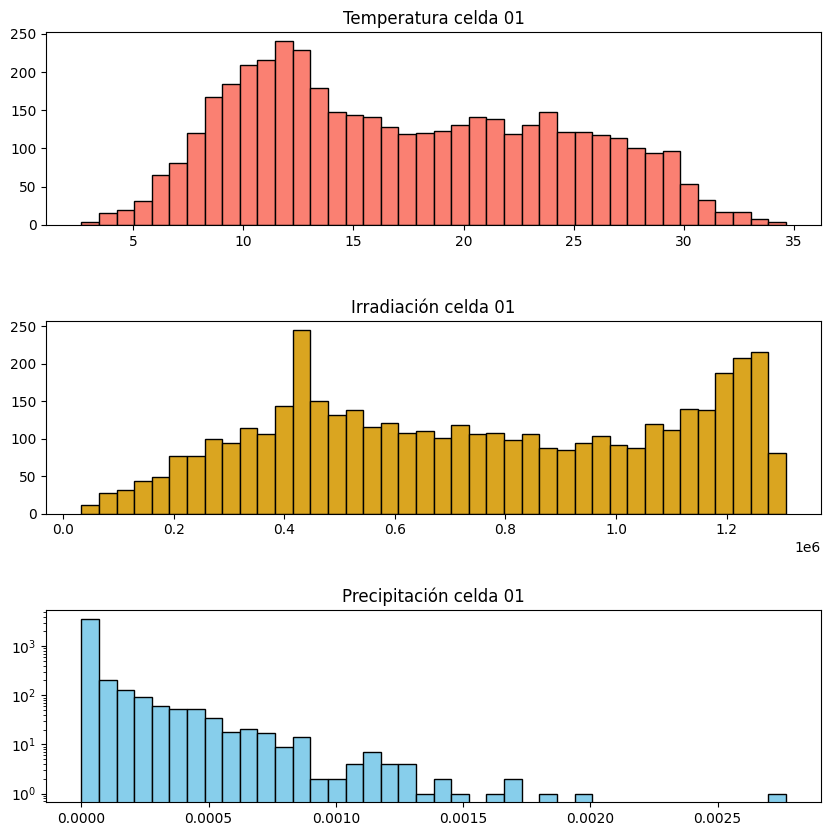

In [8]:
# histograma básico frecuencias absolutas
nbins = 40 # número de intervalos, lo estima automáticamente

fig = plt.figure(1, figsize=(10, 10)) # permite indicar el nº de la figura y las dimensiones (ancho y alto)

ax1= plt.subplot(3,1,1)
plt.hist(df_orig_temp.TEMP_CELDA01, edgecolor='black', color = 'salmon', bins = nbins)
plt.title('Temperatura celda 01')

ax2=plt.subplot(3,1,2)
plt.hist(df_orig_irrad.IRRAD_CELDA01, edgecolor='black', color = 'goldenrod', bins = nbins)
plt.title('Irradiación celda 01')

ax3=plt.subplot(3,1,3)
plt.hist(df_orig_precip.PRECIP_CELDA01, edgecolor='black', color = 'skyblue', bins = nbins, log=True) # log para mejor visualización
plt.title('Precipitación celda 01')

plt.subplots_adjust(hspace=0.5)
plt.show()

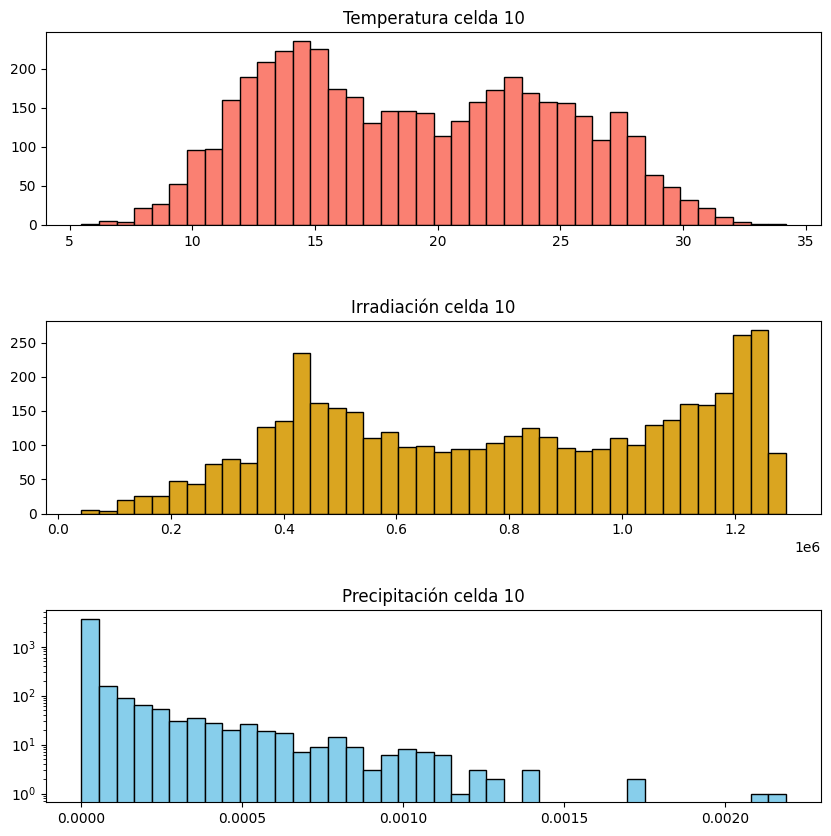

In [9]:
# histograma básico frecuencias absolutas
nbins = 40 # número de intervalos, lo estima automáticamente

fig = plt.figure(1, figsize=(10, 10)) # permite indicar el nº de la figura y las dimensiones (ancho y alto)

ax1= plt.subplot(3,1,1)
plt.hist(df_orig_temp.TEMP_CELDA10, edgecolor='black', color = 'salmon', bins = nbins)
plt.title('Temperatura celda 10')

ax2=plt.subplot(3,1,2)
plt.hist(df_orig_irrad.IRRAD_CELDA10, edgecolor='black', color = 'goldenrod', bins = nbins)
plt.title('Irradiación celda 10')

ax3=plt.subplot(3,1,3)
plt.hist(df_orig_precip.PRECIP_CELDA10, edgecolor='black', color = 'skyblue', bins = nbins, log=True) # log para mejor visualización
plt.title('Precipitación celda 10')

plt.subplots_adjust(hspace=0.5)
plt.show()

## CELDA 01

### 1.2. ¿La distribución de la temperatura en las celdas indicadas cambia con el día de la semana? ¿Y con el mes? ¿Y con el año? ¿Y la irradiación y la precipitacióncambian según el día de la semana, el mes y el año? ¿Dónde aparecen los atípicos más llamativos?


#### TEMPERATURA

In [10]:
# Estilo del boxplot
propiedades_caja = dict(facecolor='salmon', color='salmon', linewidth=2)
propiedades_mediana = dict(color='black', linewidth=3)
propiedades_bigotes = dict(color='black', linestyle='--')
propiedades_outliers = dict(marker='o', markerfacecolor='salmon', markersize=6)

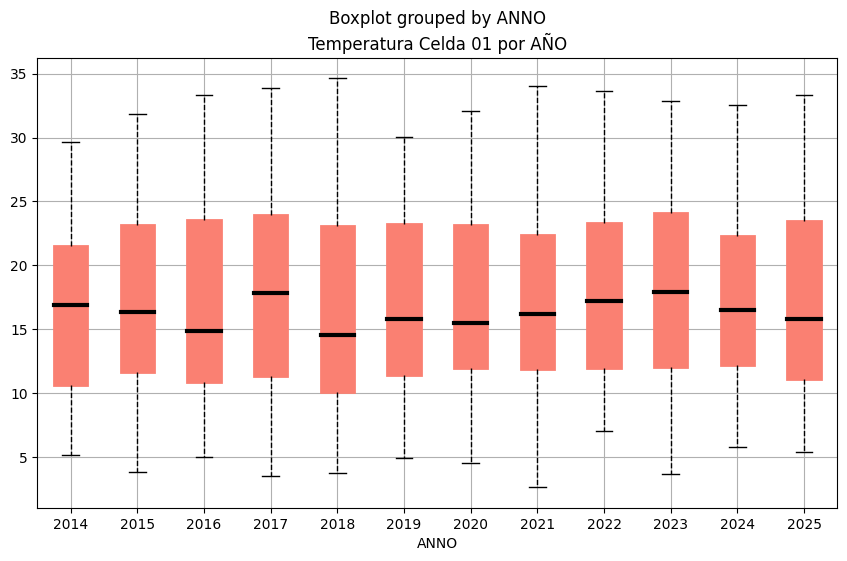

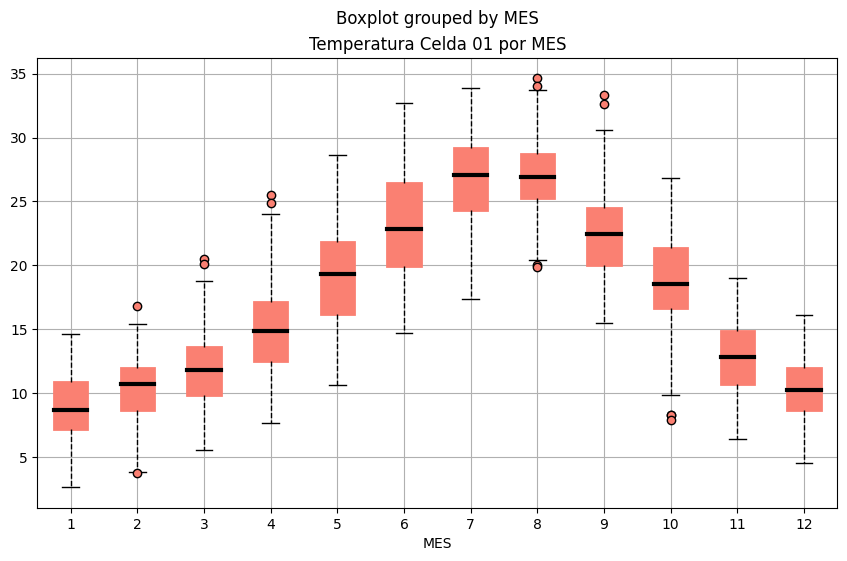

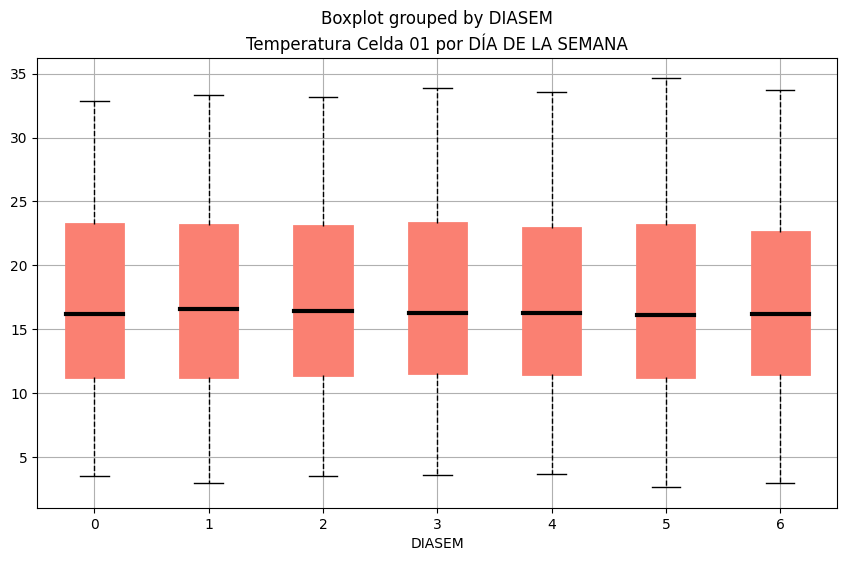

In [11]:
df_orig_temp.boxplot(column='TEMP_CELDA01', by='ANNO', figsize=(10,6), 
                     patch_artist=True,
                     boxprops=propiedades_caja, 
                     medianprops=propiedades_mediana, 
                     whiskerprops=propiedades_bigotes,
                     flierprops=propiedades_outliers)

plt.title("Temperatura Celda 01 por AÑO")
plt.show()

df_orig_temp.boxplot(column='TEMP_CELDA01', by='MES', figsize=(10,6),
                     patch_artist=True,
                     boxprops=propiedades_caja, 
                     medianprops=propiedades_mediana,
                     whiskerprops=propiedades_bigotes,
                     flierprops=propiedades_outliers)
plt.title("Temperatura Celda 01 por MES")
plt.show()

df_orig_temp.boxplot(column='TEMP_CELDA01', by='DIASEM', figsize=(10,6),
                     patch_artist=True,
                     boxprops=propiedades_caja,    
                     medianprops=propiedades_mediana,
                     whiskerprops=propiedades_bigotes,
                     flierprops=propiedades_outliers)
plt.title("Temperatura Celda 01 por DÍA DE LA SEMANA")
plt.show()

#### IRRADIACIÓN

In [12]:
# Estilo del boxplot
propiedades_caja = dict(facecolor='goldenrod', color='goldenrod', linewidth=2)
propiedades_mediana = dict(color='black', linewidth=3)
propiedades_bigotes = dict(color='black', linestyle='--')
propiedades_outliers = dict(marker='o', markerfacecolor='goldenrod', markersize=6)

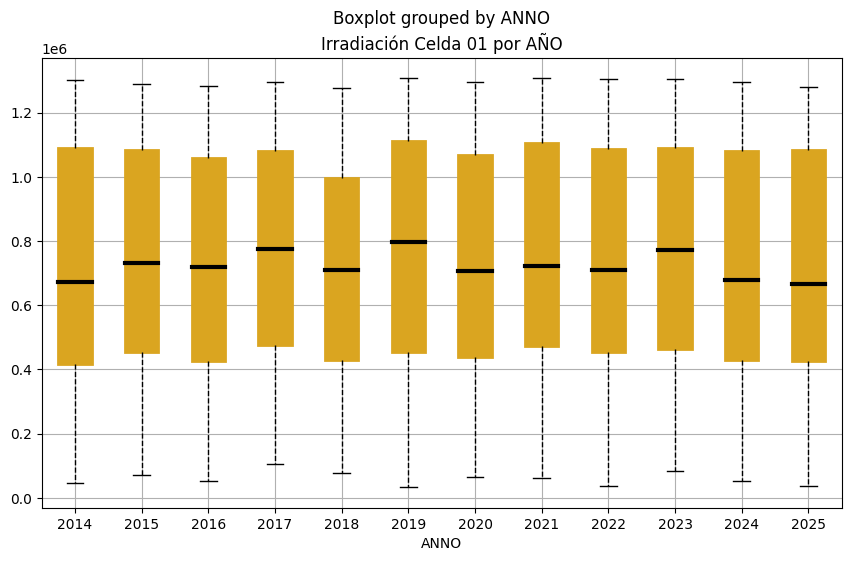

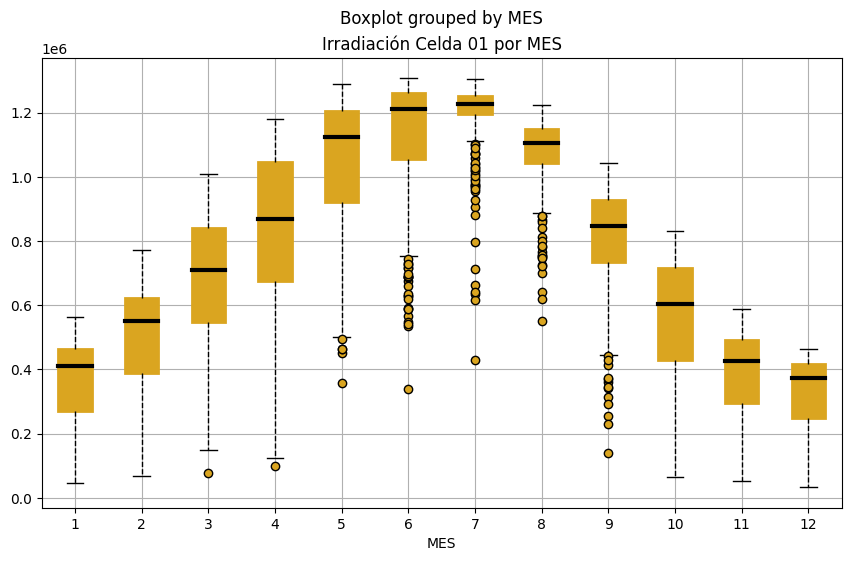

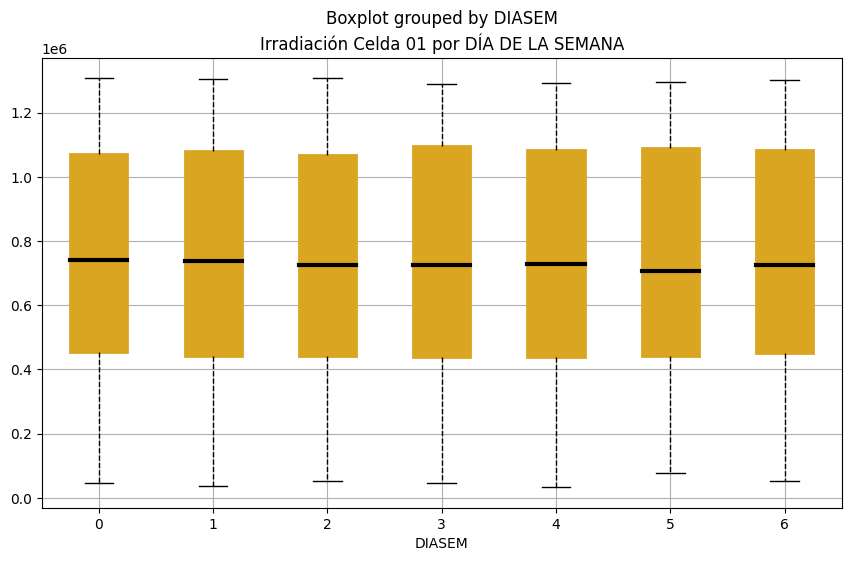

In [13]:
df_orig_irrad.boxplot(column='IRRAD_CELDA01', by='ANNO', figsize=(10,6),
                     patch_artist=True,
                     boxprops=propiedades_caja,    
                     medianprops=propiedades_mediana,
                     whiskerprops=propiedades_bigotes,
                     flierprops=propiedades_outliers)
plt.title("Irradiación Celda 01 por AÑO")
plt.show()

df_orig_irrad.boxplot(column='IRRAD_CELDA01', by='MES', figsize=(10,6),
                     patch_artist=True,
                     boxprops=propiedades_caja,    
                     medianprops=propiedades_mediana,
                     whiskerprops=propiedades_bigotes,
                     flierprops=propiedades_outliers)
plt.title("Irradiación Celda 01 por MES")
plt.show()

df_orig_irrad.boxplot(column='IRRAD_CELDA01', by='DIASEM', figsize=(10,6),
                     patch_artist=True,
                     boxprops=propiedades_caja,    
                     medianprops=propiedades_mediana,
                     whiskerprops=propiedades_bigotes,
                     flierprops=propiedades_outliers)
plt.title("Irradiación Celda 01 por DÍA DE LA SEMANA")
plt.show()

#### PRECIPITACIÓN

In [14]:
# Estilo del boxplot
propiedades_caja = dict(facecolor='skyblue', color='skyblue', linewidth=2)
propiedades_mediana = dict(color='black', linewidth=3)
propiedades_bigotes = dict(color='black', linestyle='--')
propiedades_outliers = dict(marker='o', markerfacecolor='skyblue', markersize=6)

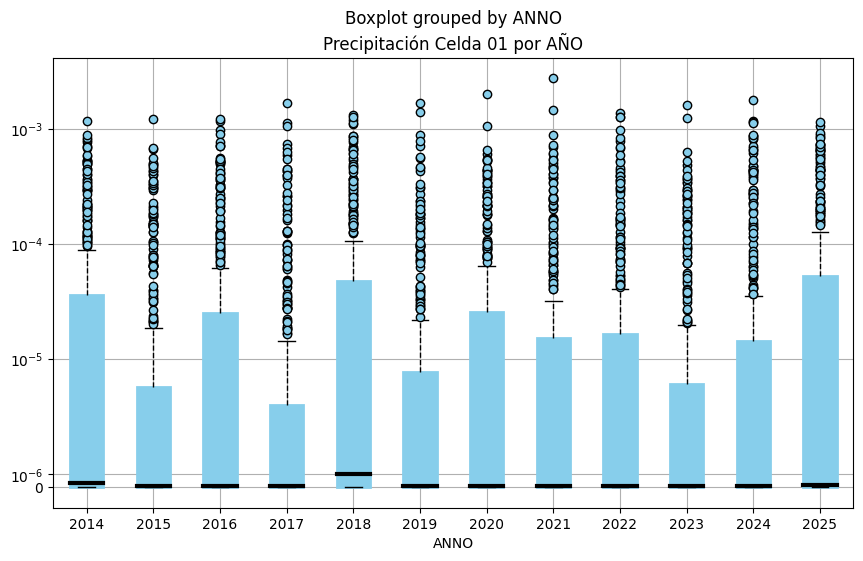

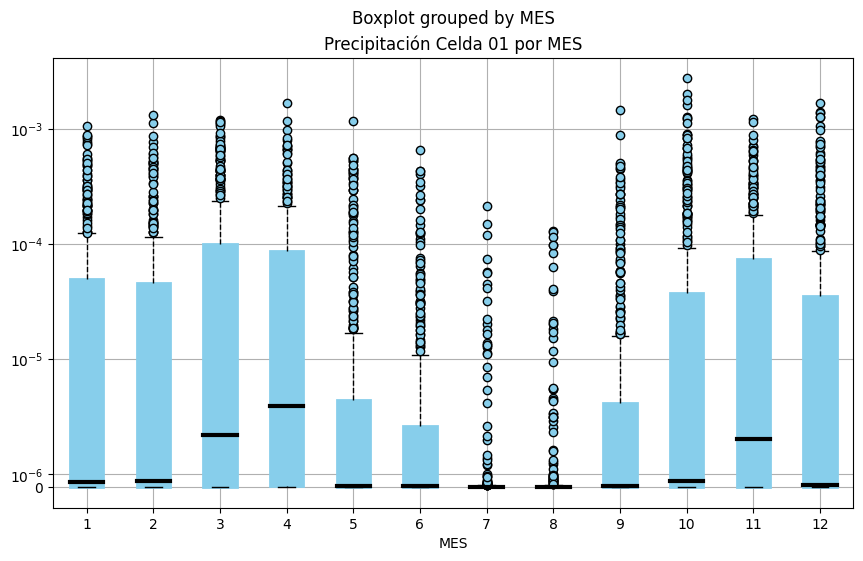

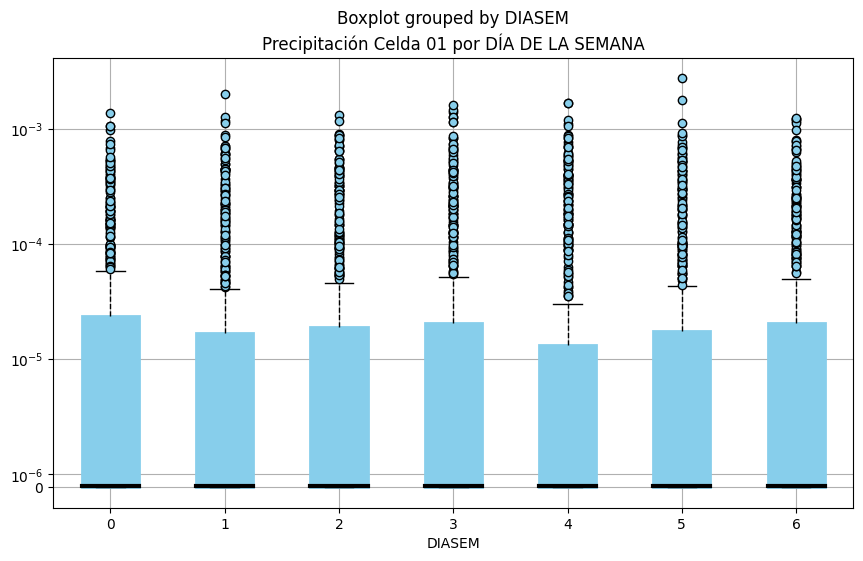

In [15]:
df_orig_precip.boxplot(column='PRECIP_CELDA01', by='ANNO', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.yscale('symlog', linthresh=1e-5) # Para mejor visualización
plt.title("Precipitación Celda 01 por AÑO")
plt.show()

df_orig_precip.boxplot(column='PRECIP_CELDA01', by='MES', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.yscale('symlog', linthresh=1e-5)
plt.title("Precipitación Celda 01 por MES")
plt.show()

df_orig_precip.boxplot(column='PRECIP_CELDA01', by='DIASEM', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.yscale('symlog', linthresh=1e-5)
plt.title("Precipitación Celda 01 por DÍA DE LA SEMANA")
plt.show()

### 1.3. ¿Qué variable meteorológica cambia más con el mes? ¿Y con el año? (Pista: usar el coeficiente de variación).


In [16]:
# groupby para agrupar por mes 
# indicamos que la columna es la celda 01

# TEMPERATURA 
cv_temp_mes = df_orig_temp.groupby('MES')['TEMP_CELDA01'].std() / df_orig_temp.groupby('MES')['TEMP_CELDA01'].mean()
print(cv_temp_mes)
# IRRADIACIÓN 
cv_irrad_mes = df_orig_irrad.groupby('MES')['IRRAD_CELDA01'].std() / df_orig_irrad.groupby('MES')['IRRAD_CELDA01'].mean()
print(cv_temp_mes)
# PRECIPITACIÓN
cv_precip_mes = df_orig_precip.groupby('MES')['PRECIP_CELDA01'].std() / df_orig_precip.groupby('MES')['PRECIP_CELDA01'].mean()
print(cv_temp_mes)

# Coeficiente de variación medio de todos los meses
print("CV Temperatura:", cv_temp_mes.mean()) 
print("CV Irradiación:", cv_irrad_mes.mean())
print("CV Precipitación:", cv_precip_mes.mean())

MES
1     0.289278
2     0.229327
3     0.221621
4     0.213771
5     0.201499
6     0.175987
7     0.114003
8     0.102492
9     0.137949
10    0.186255
11    0.202687
12    0.222926
Name: TEMP_CELDA01, dtype: float64
MES
1     0.289278
2     0.229327
3     0.221621
4     0.213771
5     0.201499
6     0.175987
7     0.114003
8     0.102492
9     0.137949
10    0.186255
11    0.202687
12    0.222926
Name: TEMP_CELDA01, dtype: float64
MES
1     0.289278
2     0.229327
3     0.221621
4     0.213771
5     0.201499
6     0.175987
7     0.114003
8     0.102492
9     0.137949
10    0.186255
11    0.202687
12    0.222926
Name: TEMP_CELDA01, dtype: float64
CV Temperatura: 0.19148293778585038
CV Irradiación: 0.24706211038409123
CV Precipitación: 3.1261640863144553


In [17]:
# TEMPERATURA 
cv_temp_anno = df_orig_temp.groupby('ANNO')['TEMP_CELDA01'].std() / df_orig_temp.groupby('ANNO')['TEMP_CELDA01'].mean()
print(cv_temp_anno)
# IRRADIACIÓN 
cv_irrad_anno = df_orig_irrad.groupby('ANNO')['IRRAD_CELDA01'].std() / df_orig_irrad.groupby('ANNO')['IRRAD_CELDA01'].mean()
print(cv_temp_anno)
# PRECIPITACIÓN
cv_precip_anno = df_orig_precip.groupby('ANNO')['PRECIP_CELDA01'].std() / df_orig_precip.groupby('ANNO')['PRECIP_CELDA01'].mean()
print(cv_temp_anno)

# Coeficiente de variación medio de todos los años
print("CV Temperatura:", cv_temp_anno.mean()) 
print("CV Irradiación:", cv_irrad_anno.mean())
print("CV Precipitación:", cv_precip_anno.mean())

ANNO
2014    0.390362
2015    0.407781
2016    0.429812
2017    0.418562
2018    0.446569
2019    0.391655
2020    0.393513
2021    0.393709
2022    0.380284
2023    0.406553
2024    0.374051
2025    0.424729
Name: TEMP_CELDA01, dtype: float64
ANNO
2014    0.390362
2015    0.407781
2016    0.429812
2017    0.418562
2018    0.446569
2019    0.391655
2020    0.393513
2021    0.393709
2022    0.380284
2023    0.406553
2024    0.374051
2025    0.424729
Name: TEMP_CELDA01, dtype: float64
ANNO
2014    0.390362
2015    0.407781
2016    0.429812
2017    0.418562
2018    0.446569
2019    0.391655
2020    0.393513
2021    0.393709
2022    0.380284
2023    0.406553
2024    0.374051
2025    0.424729
Name: TEMP_CELDA01, dtype: float64
CV Temperatura: 0.404798270853064
CV Irradiación: 0.4628752245292653
CV Precipitación: 2.9541627332918563


## CELDA 10

### 1.2. ¿La distribución de la temperatura en las celdas indicadas cambia con el día de la semana? ¿Y con el mes? ¿Y con el año? ¿Y la irradiación y la precipitacióncambian según el día de la semana, el mes y el año? ¿Dónde aparecen los atípicos más llamativos?

#### TEMPERATURA

In [18]:
# Estilo del boxplot
propiedades_caja = dict(facecolor='salmon', color='salmon', linewidth=2)
propiedades_mediana = dict(color='black', linewidth=3)
propiedades_bigotes = dict(color='black', linestyle='--')
propiedades_outliers = dict(marker='o', markerfacecolor='salmon', markersize=6)

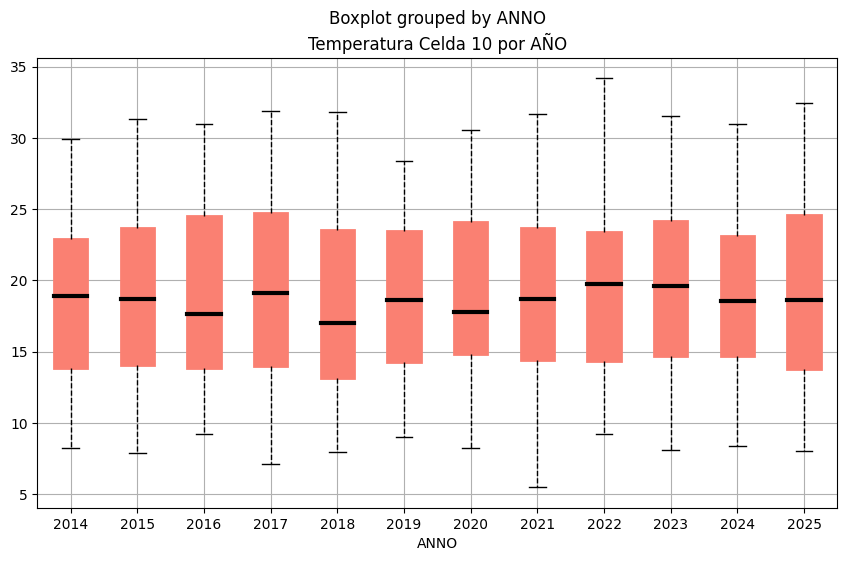

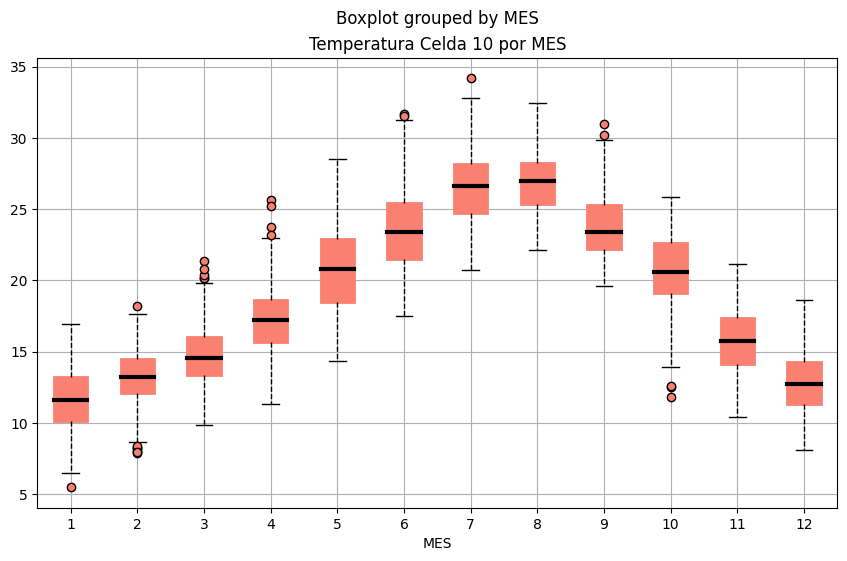

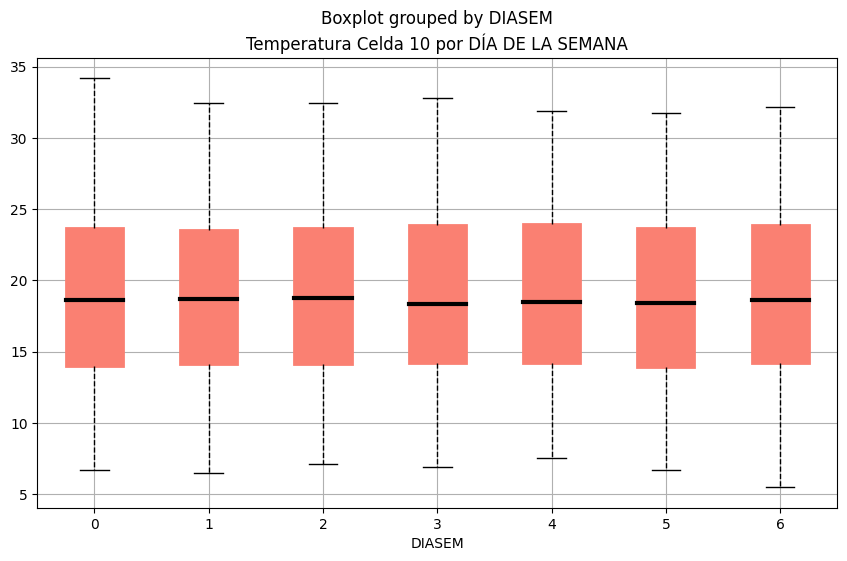

In [19]:
df_orig_temp.boxplot(column='TEMP_CELDA10', by='ANNO', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.title("Temperatura Celda 10 por AÑO")
plt.show()

df_orig_temp.boxplot(column='TEMP_CELDA10', by='MES', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.title("Temperatura Celda 10 por MES")
plt.show()

df_orig_temp.boxplot(column='TEMP_CELDA10', by='DIASEM', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.title("Temperatura Celda 10 por DÍA DE LA SEMANA")
plt.show()

#### IRRADIACIÓN

In [20]:
# Estilo del boxplot
propiedades_caja = dict(facecolor='goldenrod', color='goldenrod', linewidth=2)
propiedades_mediana = dict(color='black', linewidth=3)
propiedades_bigotes = dict(color='black', linestyle='--')
propiedades_outliers = dict(marker='o', markerfacecolor='goldenrod', markersize=6)

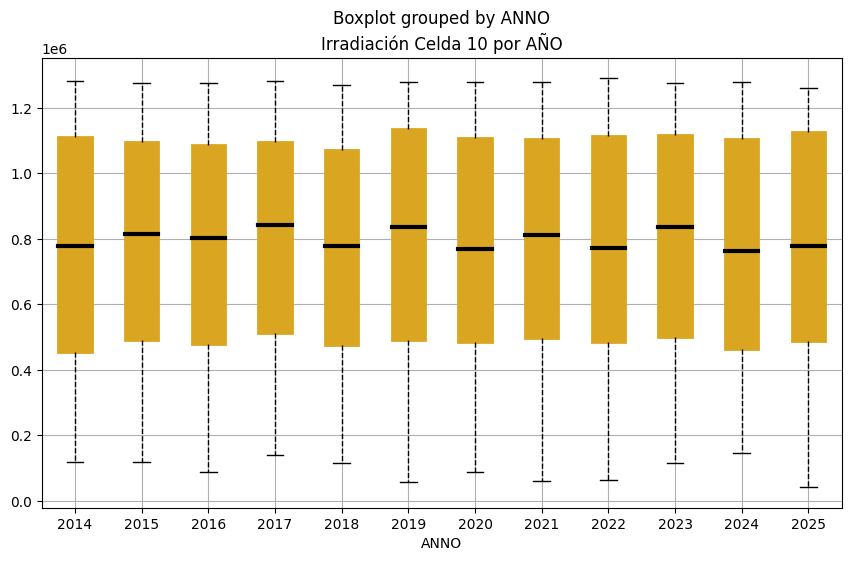

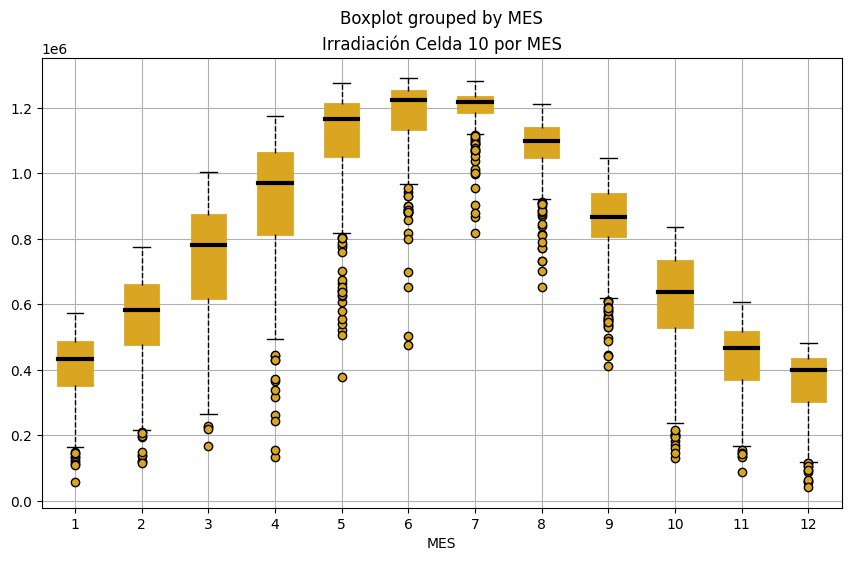

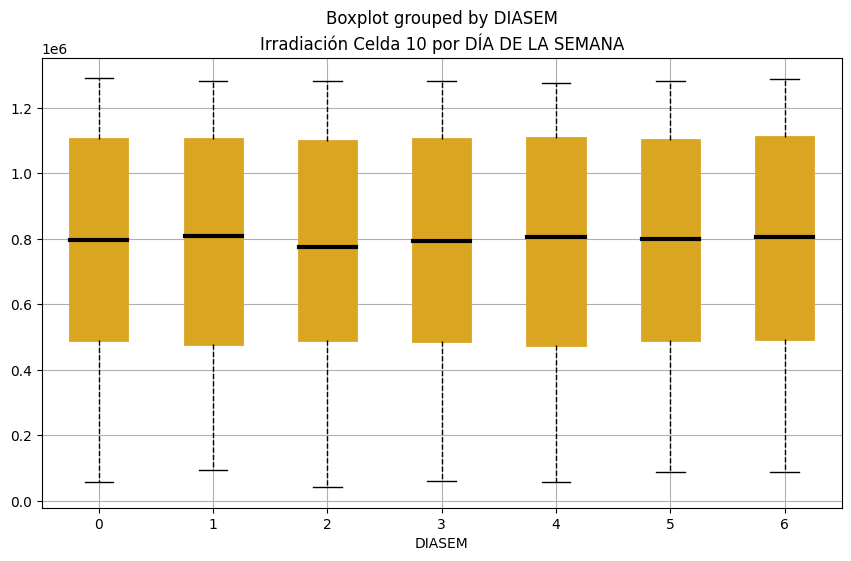

In [21]:
# IRRADIACIÓN CELDA 10
df_orig_irrad.boxplot(column='IRRAD_CELDA10', by='ANNO', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.title("Irradiación Celda 10 por AÑO")
plt.show()

df_orig_irrad.boxplot(column='IRRAD_CELDA10', by='MES', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.title("Irradiación Celda 10 por MES")
plt.show()

df_orig_irrad.boxplot(column='IRRAD_CELDA10', by='DIASEM', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.title("Irradiación Celda 10 por DÍA DE LA SEMANA")
plt.show()

#### PRECIPITACIÓN

In [22]:
# Estilo del boxplot
propiedades_caja = dict(facecolor='skyblue', color='skyblue', linewidth=2)
propiedades_mediana = dict(color='black', linewidth=3)
propiedades_bigotes = dict(color='black', linestyle='--')
propiedades_outliers = dict(marker='o', markerfacecolor='skyblue', markersize=6)

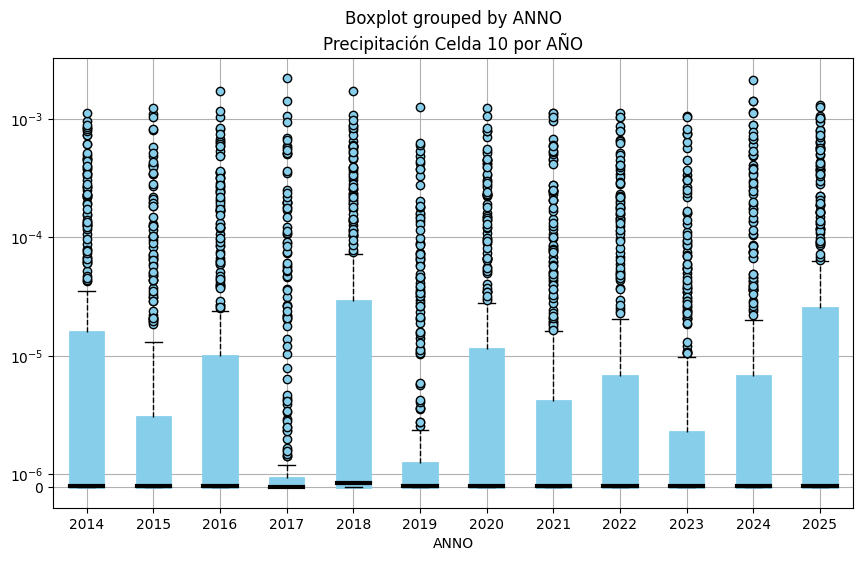

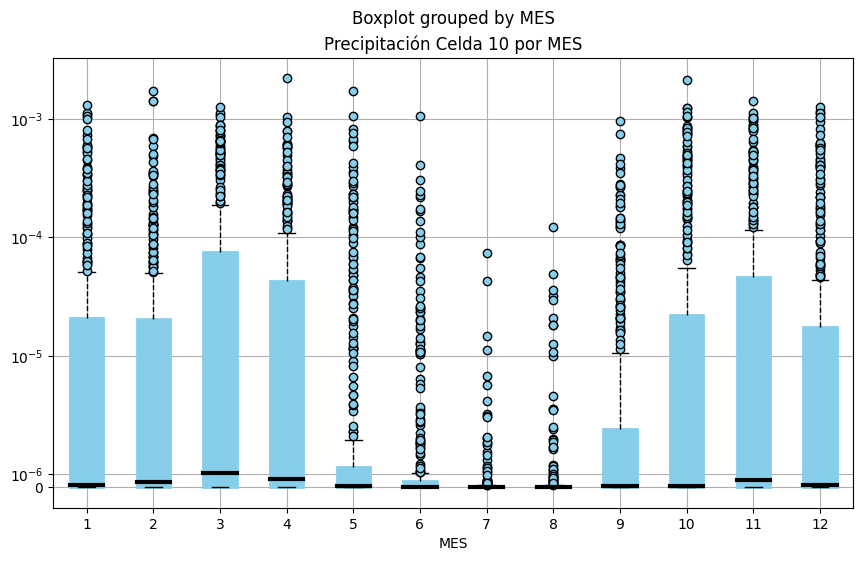

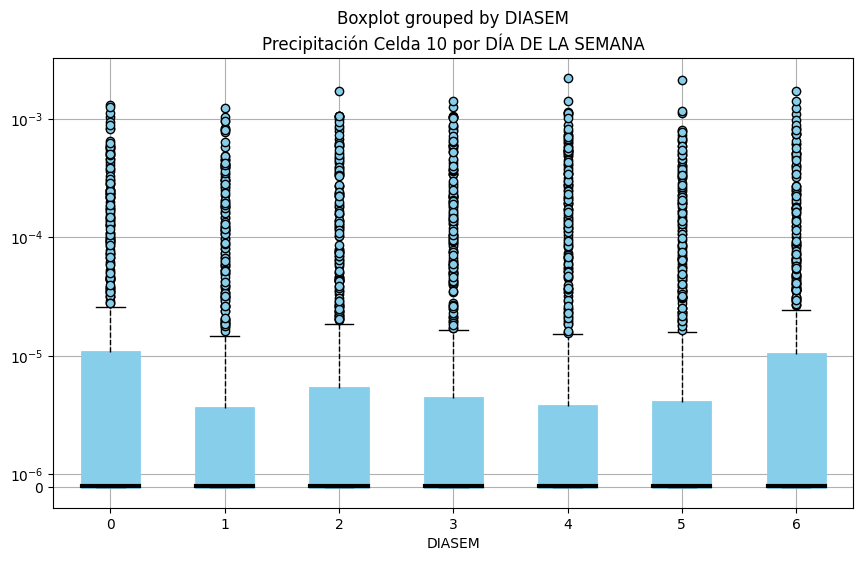

In [23]:
# PRECIPITACIÓN CELDA 10
df_orig_precip.boxplot(column='PRECIP_CELDA10', by='ANNO', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.yscale('symlog', linthresh=1e-5)
plt.title("Precipitación Celda 10 por AÑO")
plt.show()

df_orig_precip.boxplot(column='PRECIP_CELDA10', by='MES', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.yscale('symlog', linthresh=1e-5)
plt.title("Precipitación Celda 10 por MES")
plt.show()

df_orig_precip.boxplot(column='PRECIP_CELDA10', by='DIASEM', figsize=(10,6),
                         patch_artist=True,
                         boxprops=propiedades_caja,    
                         medianprops=propiedades_mediana,
                         whiskerprops=propiedades_bigotes,
                         flierprops=propiedades_outliers)
plt.yscale('symlog', linthresh=1e-5)
plt.title("Precipitación Celda 10 por DÍA DE LA SEMANA")
plt.show()

### 1.3. ¿Qué variable meteorológica cambia más con el mes? ¿Y con el año? (Pista: usar el coeficiente de variación).

In [24]:
# TEMPERATURA
cv_temp_mes = df_orig_temp.groupby('MES')['TEMP_CELDA10'].std() / df_orig_temp.groupby('MES')['TEMP_CELDA10'].mean()
print(cv_temp_mes)
# IRRADIACIÓN 
cv_irrad_mes = df_orig_irrad.groupby('MES')['IRRAD_CELDA10'].std() / df_orig_irrad.groupby('MES')['IRRAD_CELDA10'].mean()
print(cv_temp_mes)
# PRECIPITACIÓN 
cv_precip_mes = df_orig_precip.groupby('MES')['PRECIP_CELDA10'].std() / df_orig_precip.groupby('MES')['PRECIP_CELDA10'].mean()
print(cv_temp_mes)

# Coeficiente de variación medio de todos los meses
print("CV Temperatura:", cv_temp_mes.mean()) 
print("CV Irradiación:", cv_irrad_mes.mean())
print("CV Precipitación:", cv_precip_mes.mean())

MES
1     0.187483
2     0.142361
3     0.137189
4     0.132626
5     0.138823
6     0.120160
7     0.090063
8     0.077330
9     0.086145
10    0.122122
11    0.140708
12    0.156040
Name: TEMP_CELDA10, dtype: float64
MES
1     0.187483
2     0.142361
3     0.137189
4     0.132626
5     0.138823
6     0.120160
7     0.090063
8     0.077330
9     0.086145
10    0.122122
11    0.140708
12    0.156040
Name: TEMP_CELDA10, dtype: float64
MES
1     0.187483
2     0.142361
3     0.137189
4     0.132626
5     0.138823
6     0.120160
7     0.090063
8     0.077330
9     0.086145
10    0.122122
11    0.140708
12    0.156040
Name: TEMP_CELDA10, dtype: float64
CV Temperatura: 0.12758736296645573
CV Irradiación: 0.1896500314162393
CV Precipitación: 3.833044741649598


In [25]:
# TEMPERATURA 
cv_temp_anno = df_orig_temp.groupby('ANNO')['TEMP_CELDA10'].std() / df_orig_temp.groupby('ANNO')['TEMP_CELDA10'].mean()
print(cv_temp_anno)
# IRRADIACIÓN 
cv_irrad_anno = df_orig_irrad.groupby('ANNO')['IRRAD_CELDA10'].std() / df_orig_irrad.groupby('ANNO')['IRRAD_CELDA10'].mean()
print(cv_temp_anno)
# PRECIPITACIÓN
cv_precip_anno = df_orig_precip.groupby('ANNO')['PRECIP_CELDA10'].std() / df_orig_precip.groupby('ANNO')['PRECIP_CELDA10'].mean()
print(cv_temp_anno)

# Coeficiente de variación medio de todos los años
print("CV Temperatura:", cv_temp_anno.mean()) 
print("CV Irradiación:", cv_irrad_anno.mean())
print("CV Precipitación:", cv_precip_anno.mean())

ANNO
2014    0.284878
2015    0.308073
2016    0.310850
2017    0.315727
2018    0.320139
2019    0.283449
2020    0.294838
2021    0.295491
2022    0.285960
2023    0.308985
2024    0.273348
2025    0.318649
Name: TEMP_CELDA10, dtype: float64
ANNO
2014    0.284878
2015    0.308073
2016    0.310850
2017    0.315727
2018    0.320139
2019    0.283449
2020    0.294838
2021    0.295491
2022    0.285960
2023    0.308985
2024    0.273348
2025    0.318649
Name: TEMP_CELDA10, dtype: float64
ANNO
2014    0.284878
2015    0.308073
2016    0.310850
2017    0.315727
2018    0.320139
2019    0.283449
2020    0.294838
2021    0.295491
2022    0.285960
2023    0.308985
2024    0.273348
2025    0.318649
Name: TEMP_CELDA10, dtype: float64
CV Temperatura: 0.30003230229804106
CV Irradiación: 0.4174372063630653
CV Precipitación: 3.3250514910262154


## 2. Comparar las relaciones entre las 10 celdas de la temperatura, la irradiación y la precipitación.

### 2.1. ¿Cómo se relacionan los datos diarios de temperatura de la celda 01 y de la celda 10? ¿Cómo es esta relación en función del mes del año? 

Correlación entre la celda 01 y la celda 10: 0.9802465928394705


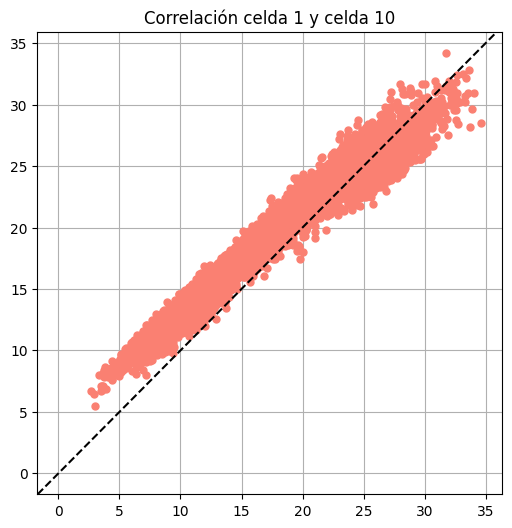

In [26]:
correlacion = df_orig_temp['TEMP_CELDA01'].corr(df_orig_temp['TEMP_CELDA10'])
print("Correlación entre la celda 01 y la celda 10:", correlacion)

# scatterplot
fig = plt.figure(1, figsize=(6, 6))
plt.plot(df_orig_temp['TEMP_CELDA01'], df_orig_temp['TEMP_CELDA10'], '.', color='salmon', markersize = 10)
plt.axline((0, 0), slope=1, color='black', linestyle='--') # y = x
plt.title("Correlación celda 1 y celda 10")
plt.grid()
plt.show()

In [27]:
# Agrupamos por mes e indicamos las dos celdas con las que queremos trabajar
matriz_mensual = df_orig_temp.groupby("MES")[["TEMP_CELDA01", "TEMP_CELDA10"]].corr()

print("Matrices de correlación por mes:")
print(matriz_mensual)

Matrices de correlación por mes:
                  TEMP_CELDA01  TEMP_CELDA10
MES                                         
1   TEMP_CELDA01      1.000000      0.928134
    TEMP_CELDA10      0.928134      1.000000
2   TEMP_CELDA01      1.000000      0.919512
    TEMP_CELDA10      0.919512      1.000000
3   TEMP_CELDA01      1.000000      0.932218
    TEMP_CELDA10      0.932218      1.000000
4   TEMP_CELDA01      1.000000      0.936603
    TEMP_CELDA10      0.936603      1.000000
5   TEMP_CELDA01      1.000000      0.923700
    TEMP_CELDA10      0.923700      1.000000
6   TEMP_CELDA01      1.000000      0.913750
    TEMP_CELDA10      0.913750      1.000000
7   TEMP_CELDA01      1.000000      0.787289
    TEMP_CELDA10      0.787289      1.000000
8   TEMP_CELDA01      1.000000      0.732366
    TEMP_CELDA10      0.732366      1.000000
9   TEMP_CELDA01      1.000000      0.897399
    TEMP_CELDA10      0.897399      1.000000
10  TEMP_CELDA01      1.000000      0.956680
    TEMP_CELDA10      

### 2.2. ¿Cómo se relacionan entre sí los datos de temperatura de las 10 celdas? ¿Se observan correlaciones no lineales entre celdas? ¿Cuáles son las celdas más correlacionadas?


Matriz correlaciones:
              TEMP_CELDA01  TEMP_CELDA02  TEMP_CELDA03  TEMP_CELDA04  \
TEMP_CELDA01       1.00000       0.99987       0.99951       0.99975   
TEMP_CELDA02       0.99987       1.00000       0.99987       0.99975   
TEMP_CELDA03       0.99951       0.99987       1.00000       0.99953   
TEMP_CELDA04       0.99975       0.99975       0.99953       1.00000   
TEMP_CELDA05       0.99950       0.99971       0.99967       0.99986   
TEMP_CELDA06       0.97915       0.97930       0.97912       0.98160   
TEMP_CELDA07       0.97937       0.97952       0.97934       0.98176   
TEMP_CELDA08       0.98028       0.98038       0.98016       0.98254   
TEMP_CELDA09       0.97900       0.97902       0.97869       0.98107   
TEMP_CELDA10       0.98025       0.98020       0.97982       0.98223   

              TEMP_CELDA05  TEMP_CELDA06  TEMP_CELDA07  TEMP_CELDA08  \
TEMP_CELDA01       0.99950       0.97915       0.97937       0.98028   
TEMP_CELDA02       0.99971       0.97930 

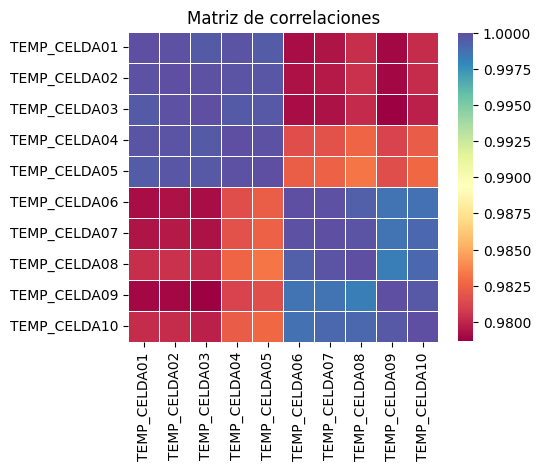

In [28]:
# matriz de correlaciones creada directamente con el dataframe (df)
mat_corr = df_orig_temp.drop(columns=['ANNO', 'MES', 'DIASEM', 'FECHA', 'DIA']).corr()                
print('Matriz correlaciones:')
print(np.round(mat_corr, 5)) # Redondeando a solo dos decimales para verlo mejor

# Muestra la matriz de correlaciones visualmente
fig = plt.figure(1,figsize=(5, 5))
sns.heatmap(mat_corr, 
            annot=False,   
            cmap = 'Spectral',
            linewidths=0.5,      
            square=True,        
            cbar_kws={"shrink": .8}) 
plt.title('Matriz de correlaciones')
plt.show()

### 2.3. Repite el análisis anterior (punto 2.2) para la irradiación y la precipitación

Matriz correlaciones:
               IRRAD_CELDA01  IRRAD_CELDA02  IRRAD_CELDA03  IRRAD_CELDA04  \
IRRAD_CELDA01        1.00000        0.99975        0.99901        0.99960   
IRRAD_CELDA02        0.99975        1.00000        0.99976        0.99950   
IRRAD_CELDA03        0.99901        0.99976        1.00000        0.99892   
IRRAD_CELDA04        0.99960        0.99950        0.99892        1.00000   
IRRAD_CELDA05        0.99919        0.99958        0.99947        0.99975   
IRRAD_CELDA06        0.97634        0.97762        0.97844        0.98023   
IRRAD_CELDA07        0.97558        0.97707        0.97811        0.97949   
IRRAD_CELDA08        0.97537        0.97704        0.97825        0.97921   
IRRAD_CELDA09        0.97050        0.97196        0.97300        0.97435   
IRRAD_CELDA10        0.97072        0.97233        0.97351        0.97451   

               IRRAD_CELDA05  IRRAD_CELDA06  IRRAD_CELDA07  IRRAD_CELDA08  \
IRRAD_CELDA01        0.99919        0.97634        0.

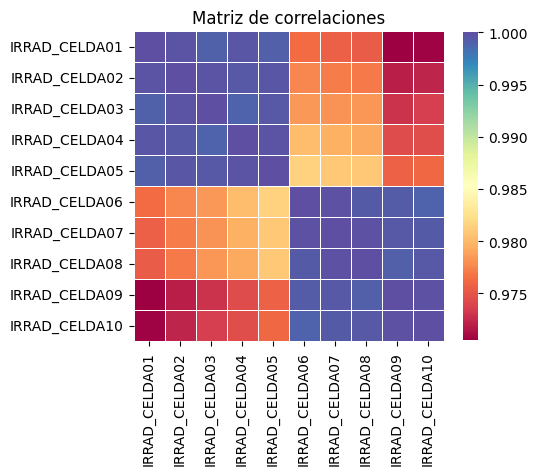

In [29]:
# matriz de correlaciones creada directamente con el dataframe (df)
mat_corr = df_orig_irrad.drop(columns=['ANNO', 'MES', 'DIASEM', 'FECHA', 'DIA']).corr()                
print('Matriz correlaciones:')
print(np.round(mat_corr, 5)) # Redondeando a solo dos decimales para verlo mejor

# Muestra la matriz de correlaciones visualmente
fig = plt.figure(1,figsize=(5, 5))
sns.heatmap(mat_corr, 
            annot=False,   
            cmap = 'Spectral',
            linewidths=0.5,      
            square=True,        
            cbar_kws={"shrink": .8}) 
plt.title('Matriz de correlaciones')
plt.show()

Matriz correlaciones:
                PRECIP_CELDA01  PRECIP_CELDA02  PRECIP_CELDA03  \
PRECIP_CELDA01         1.00000         0.99701         0.98823   
PRECIP_CELDA02         0.99701         1.00000         0.99701   
PRECIP_CELDA03         0.98823         0.99701         1.00000   
PRECIP_CELDA04         0.99349         0.99361         0.98809   
PRECIP_CELDA05         0.98750         0.99331         0.99283   
PRECIP_CELDA06         0.81847         0.83210         0.83938   
PRECIP_CELDA07         0.81815         0.83257         0.84060   
PRECIP_CELDA08         0.81760         0.83230         0.84074   
PRECIP_CELDA09         0.81240         0.82700         0.83524   
PRECIP_CELDA10         0.81302         0.82772         0.83628   

                PRECIP_CELDA04  PRECIP_CELDA05  PRECIP_CELDA06  \
PRECIP_CELDA01         0.99349         0.98750         0.81847   
PRECIP_CELDA02         0.99361         0.99331         0.83210   
PRECIP_CELDA03         0.98809         0.99283       

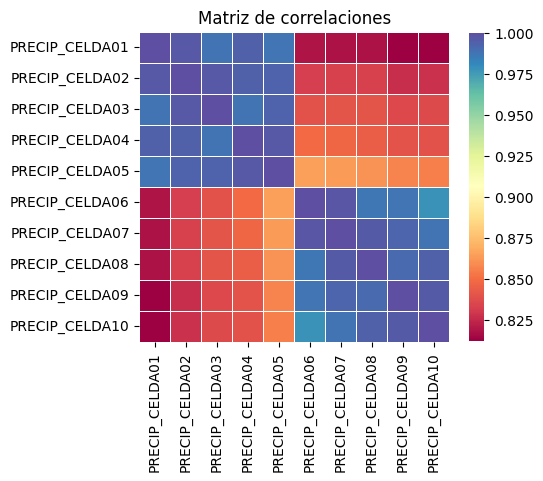

In [30]:
# matriz de correlaciones creada directamente con el dataframe (df)
mat_corr = df_orig_precip.drop(columns=['ANNO', 'MES', 'DIASEM', 'FECHA', 'DIA']).corr()                
print('Matriz correlaciones:')
print(np.round(mat_corr, 5)) # Redondeando a solo dos decimales para verlo mejor

# Muestra la matriz de correlaciones visualmente
fig = plt.figure(1,figsize=(5, 5))
sns.heatmap(mat_corr, 
            annot=False,   
            cmap = 'Spectral',
            linewidths=0.5,      
            square=True,        
            cbar_kws={"shrink": .8}) 
plt.title('Matriz de correlaciones')
plt.show()

### 2.4. ¿Cómo se relacionan la temperatura, la irradiación y la precipitación de la celda 01? 

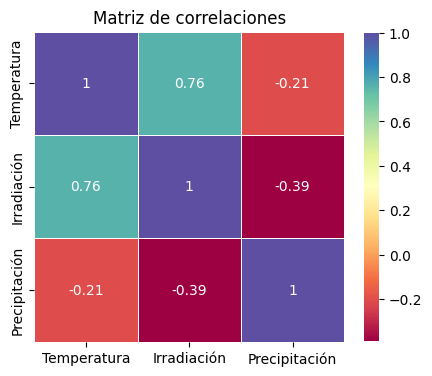

In [31]:
x = df_orig_temp.TEMP_CELDA01
y = df_orig_irrad.IRRAD_CELDA01
z = df_orig_precip.PRECIP_CELDA01

df =  pd.DataFrame(list(zip(x, y, z)), columns=['Temperatura', 'Irradiación', 'Precipitación'])

mat_corr = df.corr()

# Muestra la matriz de correlaciones visualmente
fig = plt.figure(1,figsize=(5, 5))
sns.heatmap(mat_corr, 
            annot=True,   
            cmap = 'Spectral',
            linewidths=0.5,      
            square=True,        
            cbar_kws={"shrink": .8}) 
plt.title('Matriz de correlaciones')
plt.show()

## 3. Estudio de los perfiles mensuales de temperatura e irradiación y de los perfiles anuales de precipitación.


### ¿Hay diferencias entre el perfil mensual mediano y el medio de temperatura en la celda 01? Según el perfil mediano, ¿en qué mes se alcanza el valor mínimo? ¿Y el máximo? 

In [32]:
perfil_medio = df_orig_temp.groupby("MES")[["TEMP_CELDA01"]].mean()
perfil_mediano = df_orig_temp.groupby("MES")[["TEMP_CELDA01"]].median()

print(perfil_medio)
print(perfil_mediano)

     TEMP_CELDA01
MES              
1        8.865447
2       10.310917
3       11.961350
4       14.941429
5       19.153282
6       23.122197
7       26.771053
8       26.911622
9       22.578419
10      18.817862
11      12.781915
12      10.178814
     TEMP_CELDA01
MES              
1        8.711899
2       10.738759
3       11.797282
4       14.897146
5       19.329667
6       22.843516
7       27.040532
8       26.910747
9       22.448577
10      18.534942
11      12.800229
12      10.251389


### 3.2 Dibuja la evolución mensual de los deciles (p10, p20, …, p90) de la temperatura en la celda 01 en una sola gráfica. Explica lo que observas. ¿La variabilidad de los datos mensuales de temperatura en la celda 01 es la misma para todos los meses?


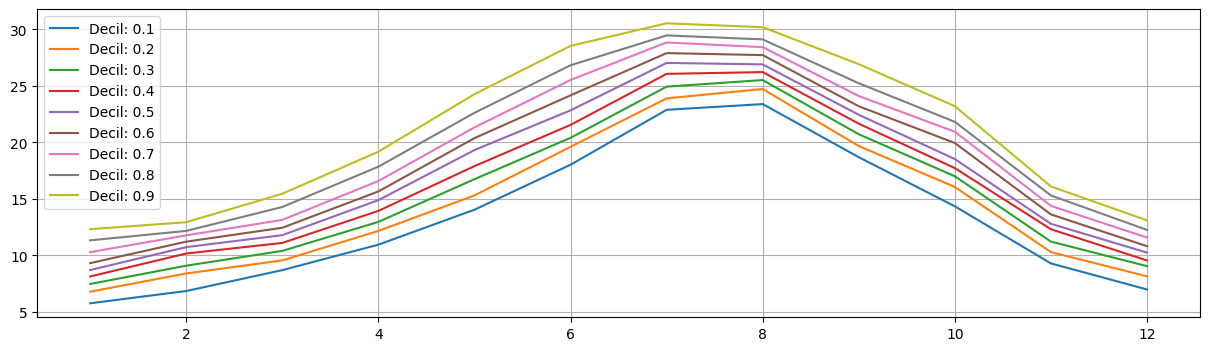

In [33]:
temp_mensual = df_orig_temp.groupby("MES")[["TEMP_CELDA01"]]
deciles_lista = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

fig = plt.figure(1, figsize=(15, 4)) 
for decil in deciles_lista:
    plt.plot(temp_mensual.quantile(decil), label = f"Decil: {decil}")     

plt.legend()
plt.grid()
plt.show()

### 3.3. Repite los análisis anteriores (puntos 3.1, 3.2 y 3.3) para la irradiación.

In [34]:
perfil_medio = df_orig_irrad.groupby("MES")[["IRRAD_CELDA01"]].mean()
perfil_mediano = df_orig_irrad.groupby("MES")[["IRRAD_CELDA01"]].median()

print(perfil_medio)
print(perfil_mediano)

     IRRAD_CELDA01
MES               
1     3.667276e+05
2     5.029149e+05
3     6.834544e+05
4     8.424492e+05
5     1.046342e+06
6     1.125293e+06
7     1.200741e+06
8     1.077680e+06
9     8.136093e+05
10    5.640821e+05
11    3.945953e+05
12    3.279956e+05
     IRRAD_CELDA01
MES               
1        411799.50
2        550204.30
3        709819.37
4        868870.72
5       1123303.55
6       1210770.50
7       1225498.45
8       1104742.25
9        846813.75
10       602274.17
11       426101.14
12       372188.09


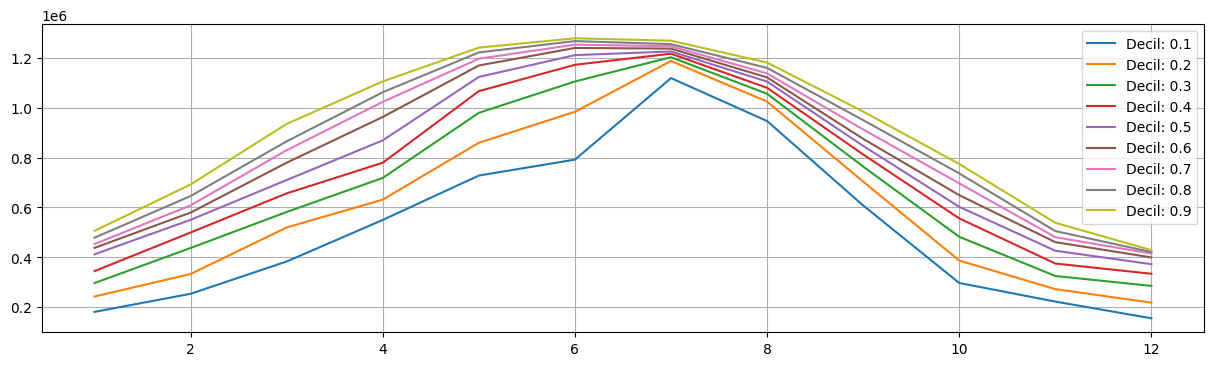

In [35]:
irrad_mensual = df_orig_irrad.groupby("MES")[["IRRAD_CELDA01"]]
deciles_lista = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

fig = plt.figure(1, figsize=(15, 4)) 
for decil in deciles_lista:
    plt.plot(irrad_mensual.quantile(decil), label = f"Decil: {decil}")     

plt.legend()
plt.grid()
plt.show()

### 3.4. Dibuja la evolución anual de los deciles (p10, p20, …, p90) de la precipitación en la celda 01 en una sola gráfica. Explica lo que observas. Según el perfil anual mediano, ¿qué año ha sido más seco? ¿Y más húmedo? ¿Cambia la variabilidad de los datos anuales con los años?


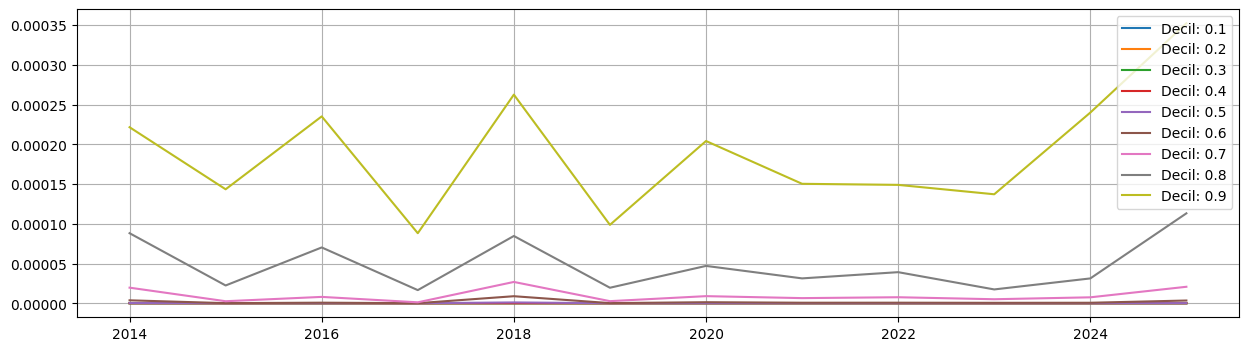

In [36]:
precip_anual = df_orig_precip.groupby("ANNO")[["PRECIP_CELDA01"]]
deciles_lista = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

fig = plt.figure(1, figsize=(15, 4)) 
for decil in deciles_lista:
    plt.plot(precip_anual.quantile(decil), label = f"Decil: {decil}")     

plt.legend()
plt.grid()
plt.show()

In [37]:
perfil_mediano = df_orig_precip.groupby("ANNO")[["PRECIP_CELDA01"]].median()
print(perfil_mediano)

      PRECIP_CELDA01
ANNO                
2014    2.970707e-07
2015    7.234246e-08
2016    1.078071e-07
2017    7.161361e-08
2018    1.070369e-06
2019    7.221888e-08
2020    1.087388e-07
2021    1.077376e-07
2022    8.998995e-08
2023    7.376419e-08
2024    8.950781e-08
2025    1.791126e-07


## 4. Estudio de la media y la varianza de la temperatura en dos grupos de celdas.

### 4.1. Basándote en las conclusiones del punto 2.2, forma dos grupos de celdas, de modo que las temperaturas de las celdas de un grupo sean similares entre sí y distintas a las del otro grupo. Justifica la elección de estos dos grupos.

In [38]:
c1 = df_orig_temp.TEMP_CELDA01
c2 = df_orig_temp.TEMP_CELDA02
c3 = df_orig_temp.TEMP_CELDA03
c4 = df_orig_temp.TEMP_CELDA04
c5 = df_orig_temp.TEMP_CELDA05
c6 = df_orig_temp.TEMP_CELDA06
c7 = df_orig_temp.TEMP_CELDA07
c8 = df_orig_temp.TEMP_CELDA08
c9 = df_orig_temp.TEMP_CELDA09
c10 = df_orig_temp.TEMP_CELDA10

grupo1 = pd.DataFrame(list(zip(c1, c2, c3, c4, c5)), columns=['CELDA01', 'CELDA02', 'CELDA03', 'CELDA04', 'CELDA05'])
grupo2 = pd.DataFrame(list(zip(c6, c7, c8, c9, c10)), columns=['CELDA06', 'CELDA07', 'CELDA08', 'CELDA09', 'CELDA10'])

### 4.2. Calcula las siguientes cuatro variables y explica cómo lo has hecho: la temperatura media y la varianza de la temperatura para cada uno de los dos grupos de celdas. Pista: cada una de estas cuatro variables es una serie temporal de datos diarios que abarca el rango de fechas original. ¿Qué grupo de celdas tiene las temperaturas más altas? ¿Y qué grupo tiene una temperatura más homogénea entre sus celdas? 

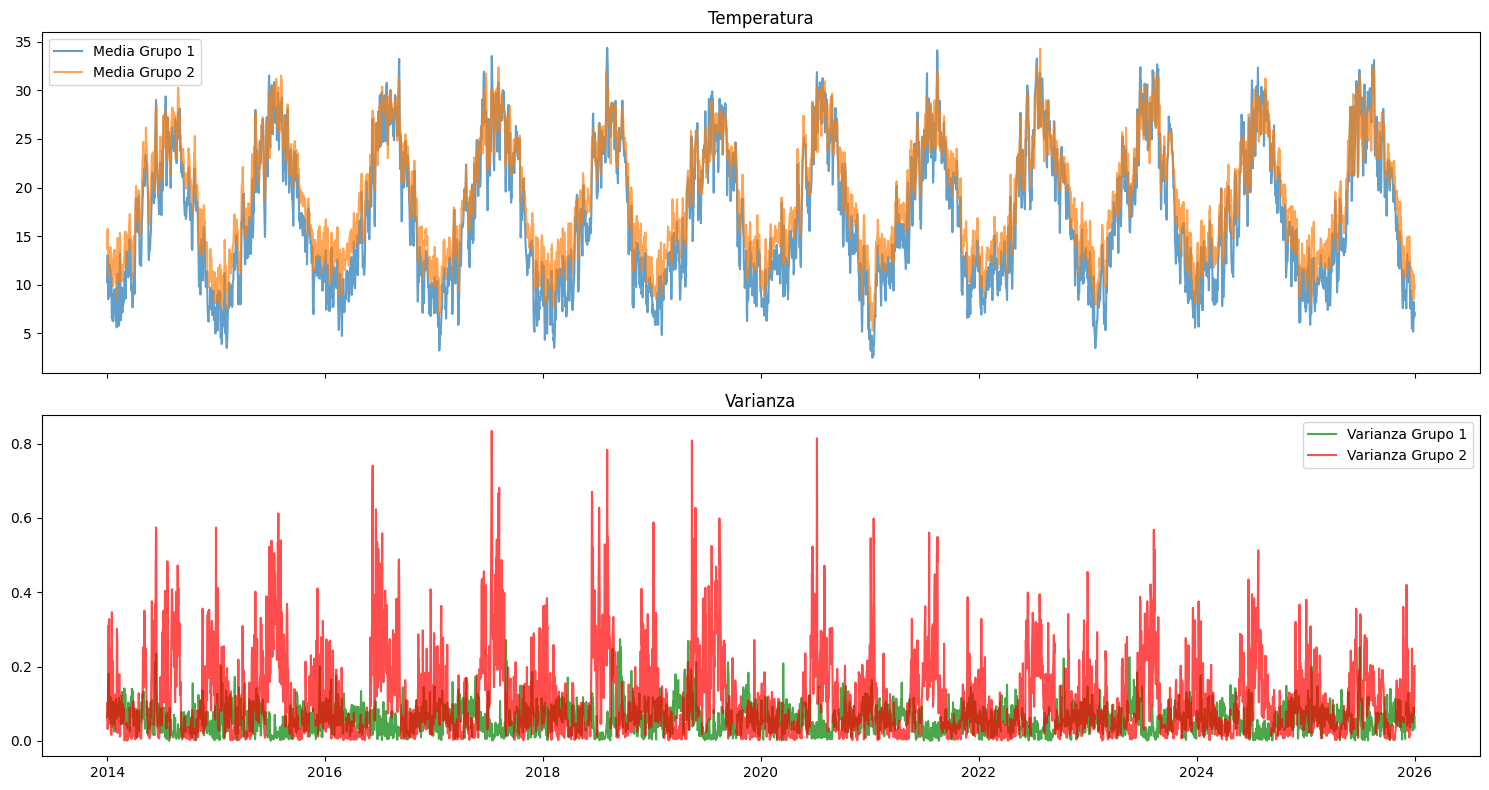

In [39]:
media_G1 = grupo1.mean(axis=1) # axis = 1 para que sume por filas
var_G1   = grupo1.var(axis=1)
media_G2 = grupo2.mean(axis=1)
var_G2   = grupo2.var(axis=1)

df_grupos = pd.DataFrame({
    'FECHA': df_orig_temp['FECHA'],
    'MES': df_orig_temp['MES'],
    'ANNO': df_orig_temp['ANNO'],
    'MEDIA_G1': media_G1,
    'VAR_G1': var_G1,
    'MEDIA_G2': media_G2,
    'VAR_G2': var_G2
})


fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15, 8), sharex=True)

axes[0].plot(df_grupos.FECHA, df_grupos.MEDIA_G1, label='Media Grupo 1', alpha = 0.7)
axes[0].plot(df_grupos.FECHA, df_grupos.MEDIA_G2, label='Media Grupo 2', alpha = 0.7)
axes[0].set_title('Temperatura')
axes[0].legend()


axes[1].plot(df_grupos.FECHA, df_grupos.VAR_G1, label='Varianza Grupo 1', color='green', alpha = 0.7)
axes[1].plot(df_grupos.FECHA, df_grupos.VAR_G2, label='Varianza Grupo 2', color='red', alpha = 0.7)
axes[1].set_title('Varianza')
axes[1].legend()

plt.tight_layout()
plt.show()

### 4.3. ¿Cómo cambia la correlación entre las temperaturas medias de los dos grupos con los meses? ¿En qué mes las temperaturas medias están más correlacionadas? ¿Y en cuál lo están menos? 

In [40]:
# Agrupamos por mes y calculamos la correlación
mat_medias = df_grupos.groupby('MES')[['MEDIA_G1', 'MEDIA_G2']].corr()

# .xs para quedarnos solo con el cruce entre G1 y G2
corr= mat_medias.xs('MEDIA_G1', level=1)['MEDIA_G2']

print("Correlación de medias por mes:")
print(corr)

Correlación de medias por mes:
MES
1     0.931438
2     0.923193
3     0.936471
4     0.939130
5     0.926878
6     0.914077
7     0.782128
8     0.726136
9     0.903898
10    0.959688
11    0.928842
12    0.927275
Name: MEDIA_G2, dtype: float64


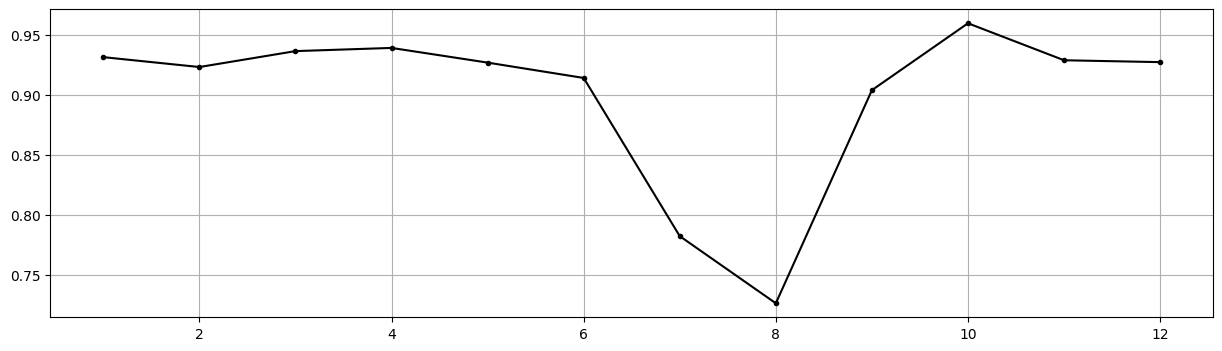

In [41]:
fig = plt.figure(1, figsize=(15, 4)) # permite indicar el nº de la figura y las dimensiones (ancho y alto)
plt.plot(corr, 'k.-')                  # muestra la variable x en negro, cada valor con un punto conectados por líneas
plt.grid()
plt.show()

### 4.4. Responde a la pregunta anterior (punto 4.3) usando como variables las varianzas de la temperatura de los dos grupos.

In [42]:
# Agrupamos por mes y calculamos la correlación
mat_varianzas = df_grupos.groupby('MES')[['VAR_G1', 'VAR_G2']].corr()

# .xs para quedarnos solo con el cruce entre G1 y G2
corr= mat_varianzas.xs('VAR_G1', level=1)['VAR_G2']

print("Correlación de varianzas por mes:")
print(corr)

Correlación de varianzas por mes:
MES
1    -0.079673
2     0.037617
3    -0.099958
4    -0.112587
5    -0.029945
6    -0.073581
7    -0.269092
8    -0.193792
9    -0.252933
10   -0.053919
11   -0.106149
12   -0.118305
Name: VAR_G2, dtype: float64


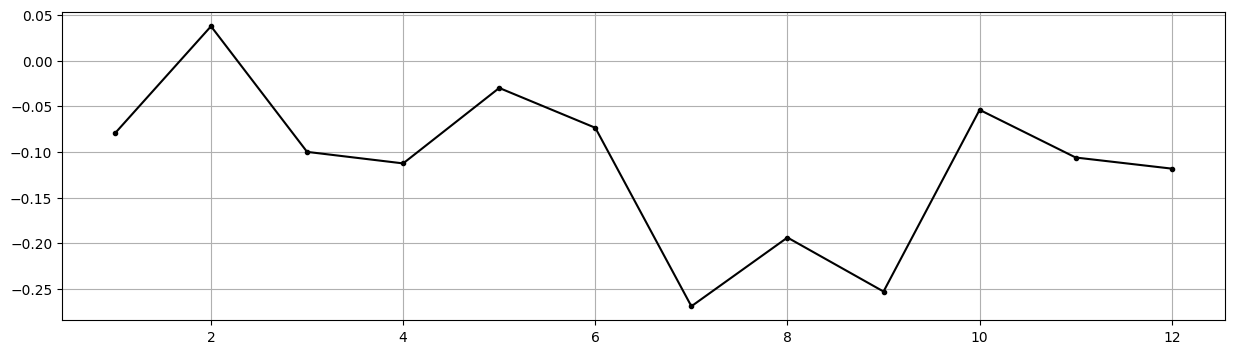

In [43]:
fig = plt.figure(1, figsize=(15, 4)) # permite indicar el nº de la figura y las dimensiones (ancho y alto)
plt.plot(corr, 'k.-')                  # muestra la variable x en negro, cada valor con un punto conectados por líneas
plt.grid()
plt.show()